# LINE vs. DEXTER and DiffExplainer on a robust ResNet50

Recreates the paper's comparison with DEXTER and DiffExplainer. For five `avgpool` neurons
of an adversarially robust ResNet50 in each of six ImageNet classes, every row shows one
image per neuron and the neuron's activation on it (the highest activation per neuron in
bold).

The images are in `assets/dexter/`. The DEXTER, DiffExplainer and Salient ImageNet images
were provided on request by the authors of
[DEXTER](https://arxiv.org/abs/2510.14741) (Carnemolla et al., 2025), whom we thank. The robust ResNet50 weights are downloaded to
`$DATA_DIR/models/` on the first run.

In [1]:
import csv
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm without ipywidgets

REPO = Path.cwd().parent
ASSETS = REPO / "assets" / "dexter"
assert ASSETS.is_dir(), "run this notebook from the notebooks/ directory"
sys.path.insert(0, str(REPO))  # explained_models.py and transform_images.py
os.environ.setdefault("DATA_DIR", str(REPO / "data"))

from explained_models import get_model  # noqa: E402
from transform_images import get_transform  # noqa: E402

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 72

MODEL_ID = "resnet50|robust"
model = get_model(MODEL_ID, ["avgpool"], torch.device("cpu"), model_swapping=False)
transform = get_transform(MODEL_ID)

with open(ASSETS / "concepts.csv") as f:
    rows = list(csv.DictReader(f))
CLASSES = {int(r["label"]): r["class_name"] for r in rows}
NEURONS = {label: [int(r["neuron"]) for r in rows if int(r["label"]) == label] for label in CLASSES}
CONCEPTS = {(int(r["label"]), int(r["neuron"])): r["concept"] for r in rows}

In [2]:
def activations(images: list[Image.Image]) -> torch.Tensor:
    """avgpool activations, one row per image."""
    return model.get_activations(transform(images))["avgpool"]


def method_row(label: int, method: str) -> dict:
    """One image per neuron, and each neuron's activation on its own image."""
    images = [Image.open(ASSETS / str(label) / f"{method}_{col}.jpg") for col in range(5)]
    values = activations(images)[:, NEURONS[label]].diagonal()
    return {"method": method, "images": images, "activations": values.tolist()}


def line_row(label: int) -> dict:
    """For each neuron, the top-activating of LINE's five images of its reported concept."""
    images, values, concepts = [], [], []
    for neuron in NEURONS[label]:
        folder = ASSETS / str(label) / "LINE" / f"neuron_{neuron}"
        candidates = [Image.open(folder / f"image_{i}.jpeg") for i in range(1, 6)]
        neuron_values = activations(candidates)[:, neuron]
        best = int(neuron_values.argmax())
        images.append(candidates[best])
        values.append(neuron_values[best].item())
        concepts.append(CONCEPTS[(label, neuron)])
    return {"method": "LINE", "images": images, "activations": values, "concepts": concepts}


def salient_row(label: int) -> dict:
    """The neurons' heatmaps from Salient ImageNet (no activations)."""
    images = [Image.open(ASSETS / str(label) / f"SalientImageNet_{col}.jpg") for col in range(5)]
    return {"method": "Salient ImageNet", "images": images, "activations": None}


ROWS = {
    label: {"Salient ImageNet": salient_row(label), "DiffExplainer": method_row(label, "DiffExplainer"),
            "DEXTER": method_row(label, "DEXTER"), "LINE": line_row(label)}
    for label in CLASSES
}

pd.DataFrame([
    {"label": f"{label} ({CLASSES[label]})", "neuron": neuron,
     **{m: ROWS[label][m]["activations"][col] for m in ["DiffExplainer", "DEXTER", "LINE"]},
     "LINE concept": CONCEPTS[(label, neuron)]}
    for label in CLASSES for col, neuron in enumerate(NEURONS[label])
]).set_index(["label", "neuron"]).round(2)

DiffExplainer  DEXTER   LINE  \
label             neuron                                 
609 (Jeep)        1067            10.52    3.01   6.02   
                  1100             7.09    0.66   2.74   
                  1208             0.03    2.50   3.94   
                  1515             1.47    0.57   3.01   
                  691              5.77    2.84   4.13   
985 (Daisy)       1105             6.60    0.36   4.70   
                  120              7.89    3.61   2.95   
                  298             13.77    3.57   6.29   
                  595             17.01   12.64  12.03   
                  859              6.74    2.70   4.10   
764 (Rifle)       1259             9.81    2.45   2.30   
                  1928             4.21    0.53   2.80   
                  400              4.78    3.72   2.87   
                  515              8.20    1.86   2.67   
                  522             10.63    3.11   4.50   
706 (Patio)       1016             5.98    4.85   2.94   
                  1633             6.57    1.83   4.55   
                  194             12.93    3.73   2.57   
                  451              9.84    4.14   3.24   
                  654              5.13    1.35   3.20   
433 (Bathing Cap) 121              3.42    2.51   1.99   
                  1340            13.18    1.48   8.01   
                  1591             7.84    2.67   7.09   
                  1609             5.38    2.11   5.78   
                  755             11.58    2.77   1.60   
785 (Seat Belt)   1010             5.45    1.14   1.49   
                  108              2.11    3.00   4.53   
                  116              6.07    2.71   2.76   
                  1493             3.97    1.85   2.55   
                  50               5.77    0.56   2.28   

                                      LINE concept  
label             neuron                            
609 (Jeep)        1067                    golfcart  
                  1100    european fire salamander  
                  1208                     tractor  
                  1515                      pickup  
                  691                    limousine  
985 (Daisy)       1105    sulphur-crested cockatoo  
                  120                ground beetle  
                  298                        spiny  
                  595                        daisy  
                  859                  tick spider  
764 (Rifle)       1259                    revolver  
                  1928                      tripod  
                  400                  grand piano  
                  515                gun accessory  
                  522                     revolver  
706 (Patio)       1016                sliding door  
                  1633                      oxcart  
                  194                         ipod  
                  451                     golfcart  
                  654                 barber chair  
433 (Bathing Cap) 121                         head  
                  1340                    swimsuit  
                  1591                     macaque  
                  1609                  shower cap  
                  755            graduation attire  
785 (Seat Belt)   1010               scooter mower  
                  108                eye coverings  
                  116                   car mirror  
                  1493                  car mirror  
                  50                    car mirror

In [3]:
def draw(label: int, methods: list[str], title: bool) -> None:
    rows = [ROWS[label][m] for m in methods]
    scored = np.array([row["activations"] for row in rows if row["activations"] is not None])
    best = scored.max(axis=0)
    fig, axes = plt.subplots(
        len(rows), 5,
        figsize=(5 * (2.7 if title else 3.0), len(rows) * (3.0 if title else 2.55)),
        gridspec_kw={"wspace": 0.05, "hspace": 0.4 if title else 0.25},
    )
    if title:
        fig.suptitle(f"Label {label} ({CLASSES[label]})", fontsize=25, fontweight="bold", y=0.95)
    for r, row in enumerate(rows):
        labels = [c.replace("_", " ") for c in row.get("concepts", [])]
        labels = [c.replace(" ", "\n") if len(c) > 15 else c for c in labels]
        if any("\n" in c for c in labels):  # keep the captions of one row on the same baseline
            labels = [c if "\n" in c else c + "\n" for c in labels]
        for c in range(5):
            ax = axes[r, c]
            ax.imshow(row["images"][c].resize((512, 512)))
            if row["activations"] is None:
                ax.set_title(f"Feature {NEURONS[label][c]}", fontsize=18)
            else:
                value = row["activations"][c]
                ax.set_title(f"Activation: {value:.2f}", fontsize=16, pad=8,
                             fontweight="bold" if value == best[c] else "normal")
            if c == 0:
                ax.set_ylabel(row["method"], fontsize=18, labelpad=10, fontweight="bold")
            ax.set_xlabel(labels[c] if labels else " ", fontsize=18 if labels else 14, labelpad=10)
            ax.set_xticks([])
            ax.set_yticks([])
    plt.show()

## Main figure

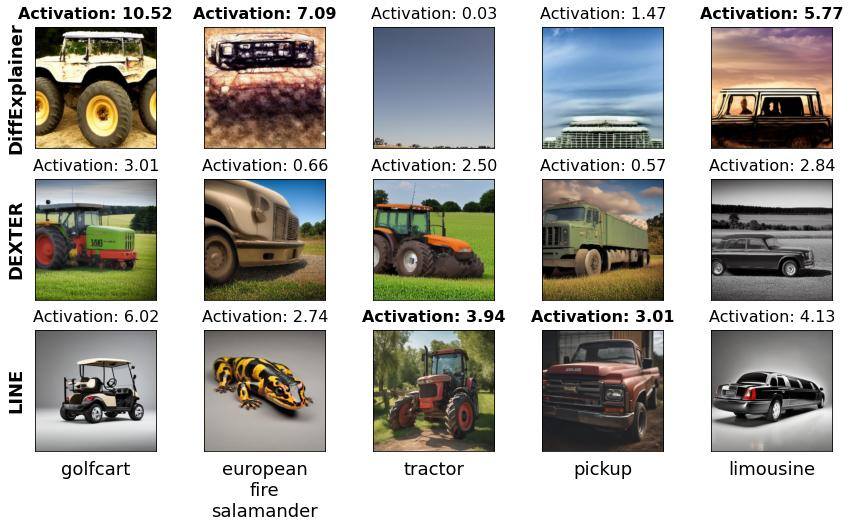

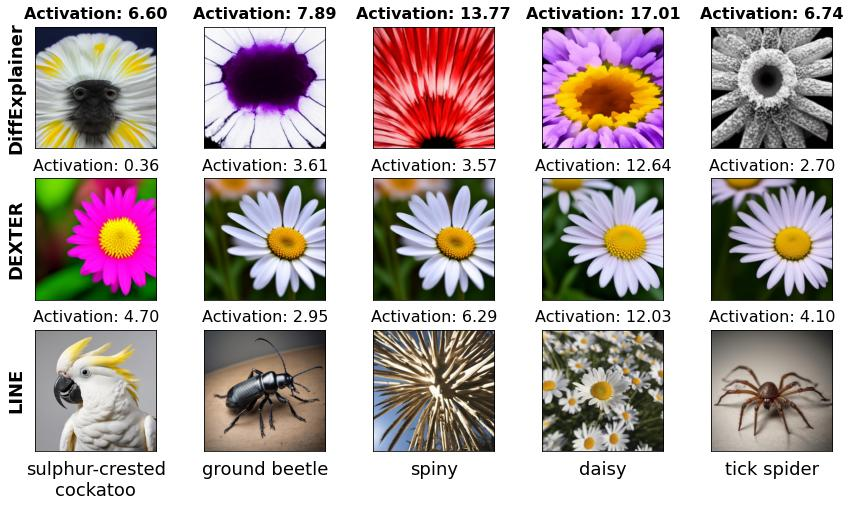

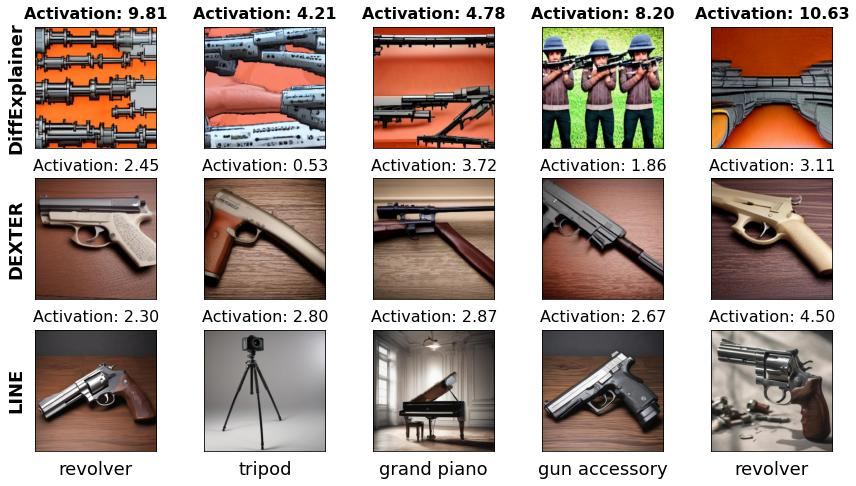

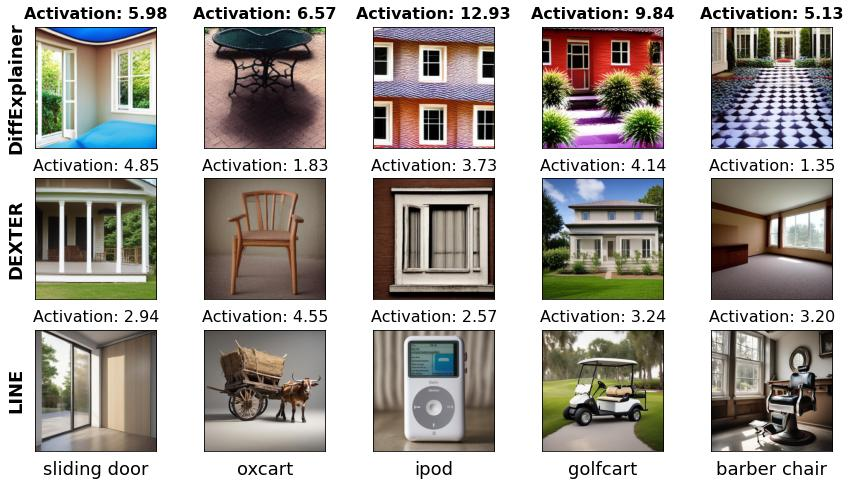

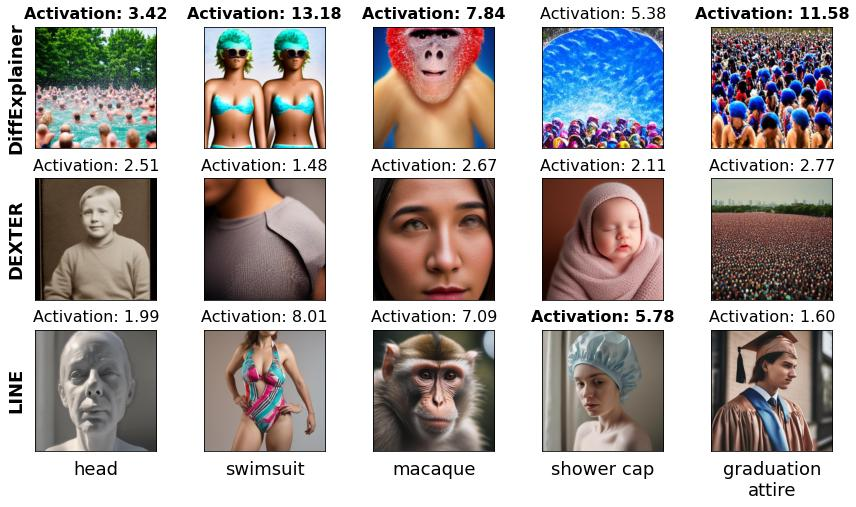

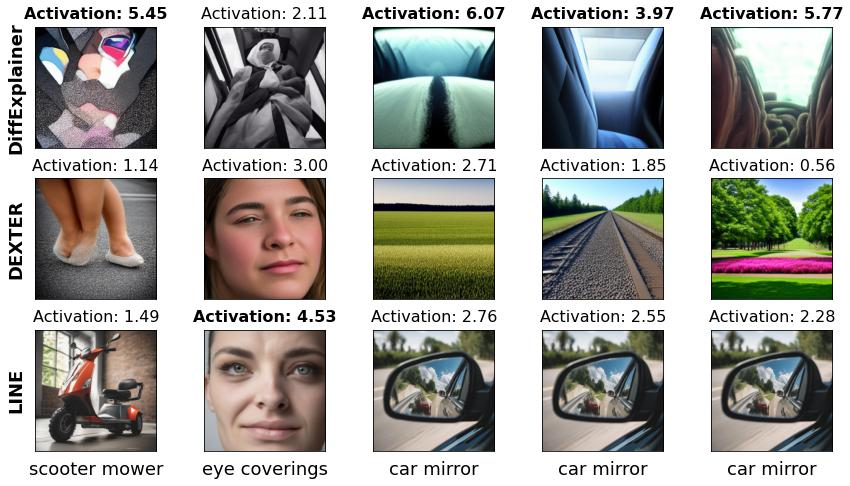

In [4]:
for label in CLASSES:
    draw(label, ["DiffExplainer", "DEXTER", "LINE"], title=False)

## Appendix: with the Salient ImageNet heatmaps

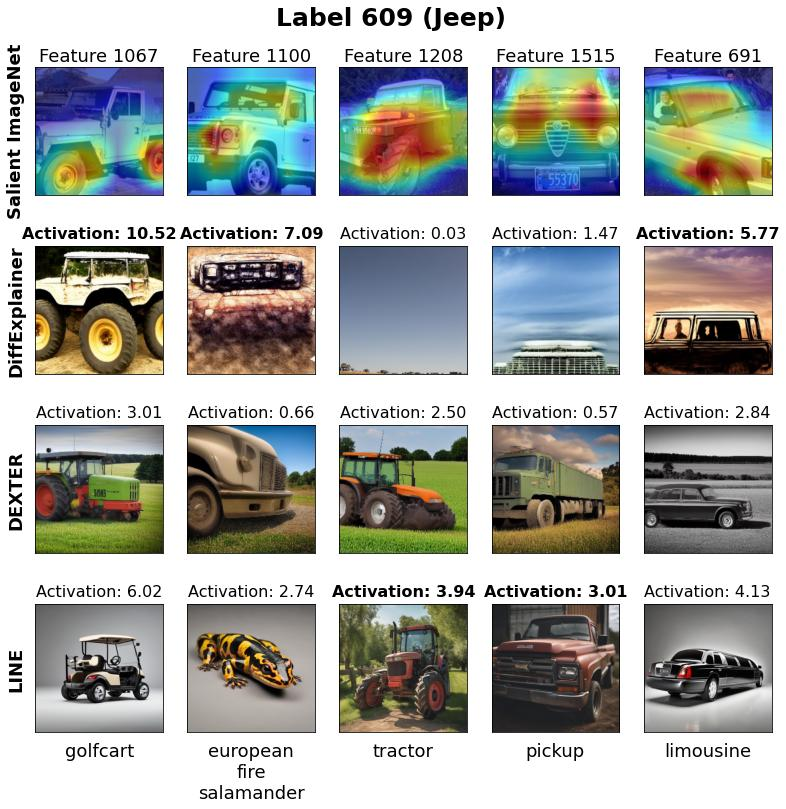

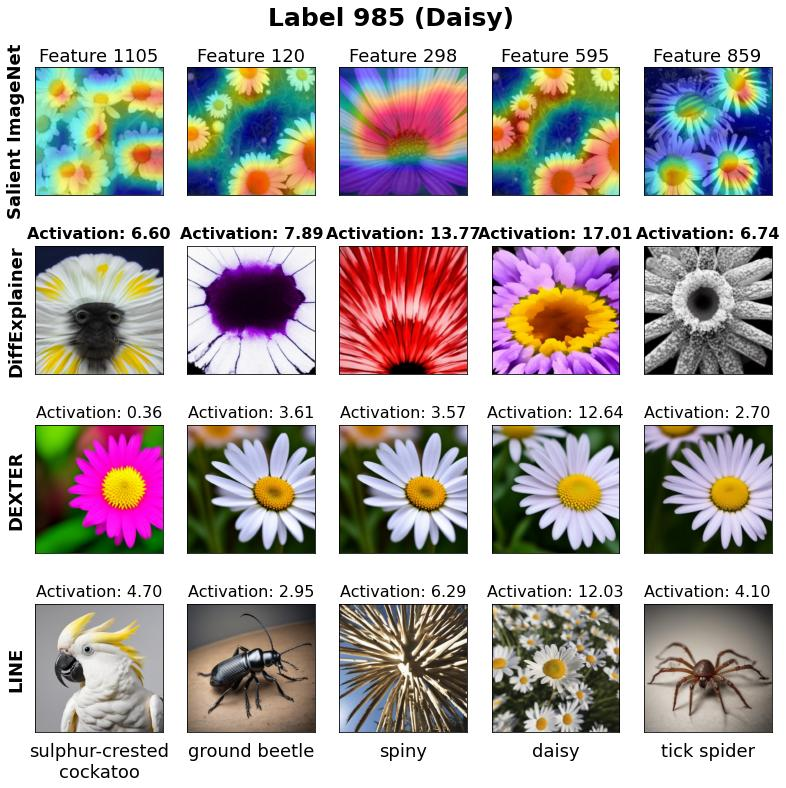

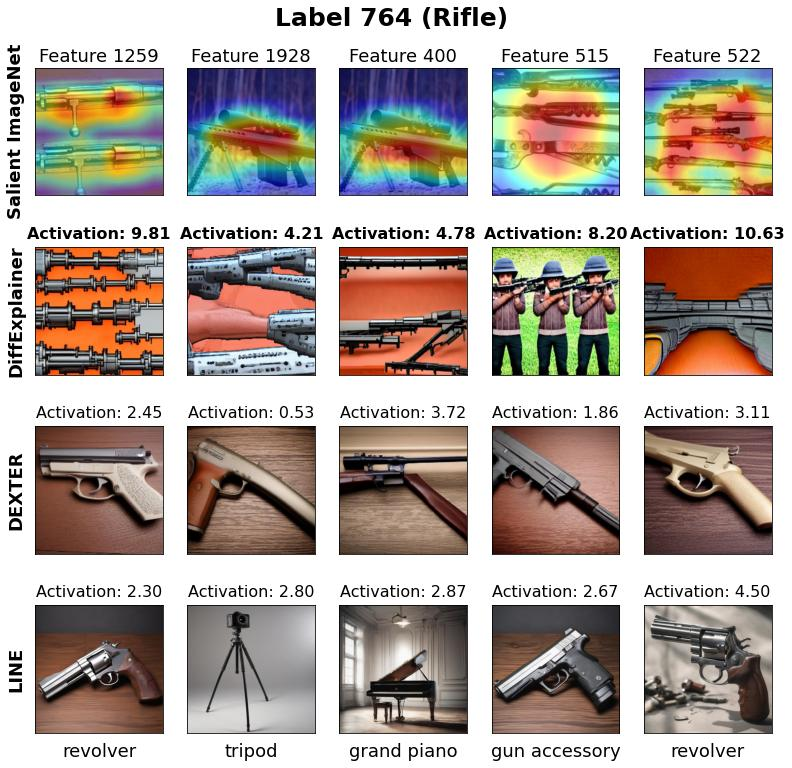

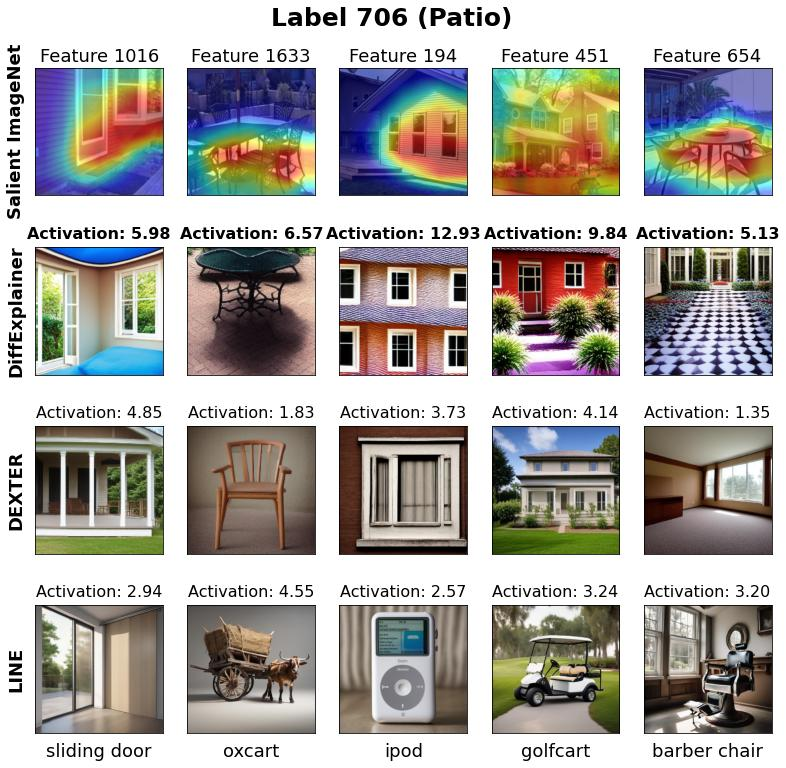

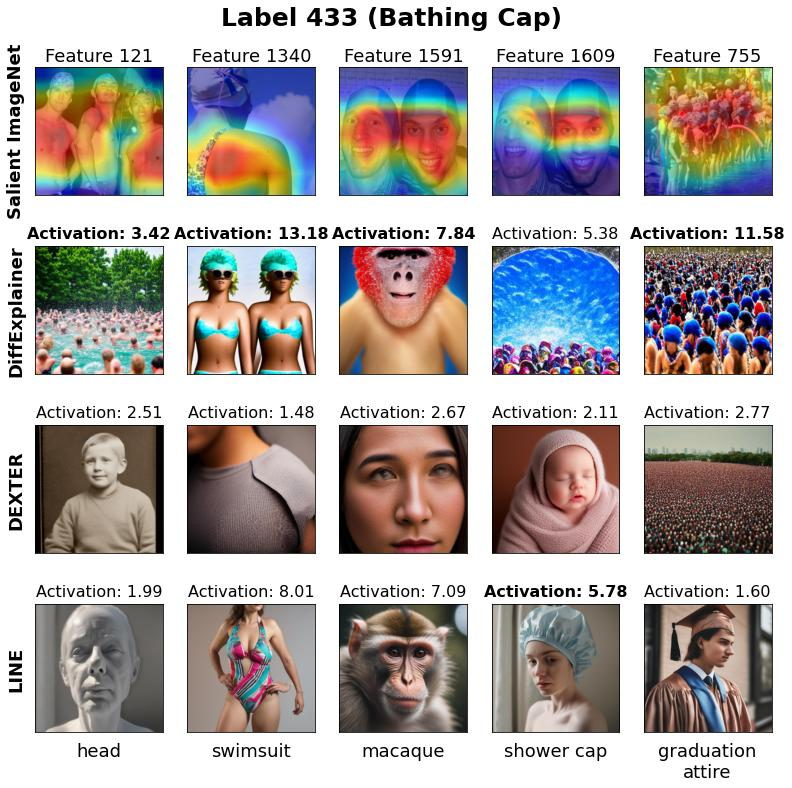

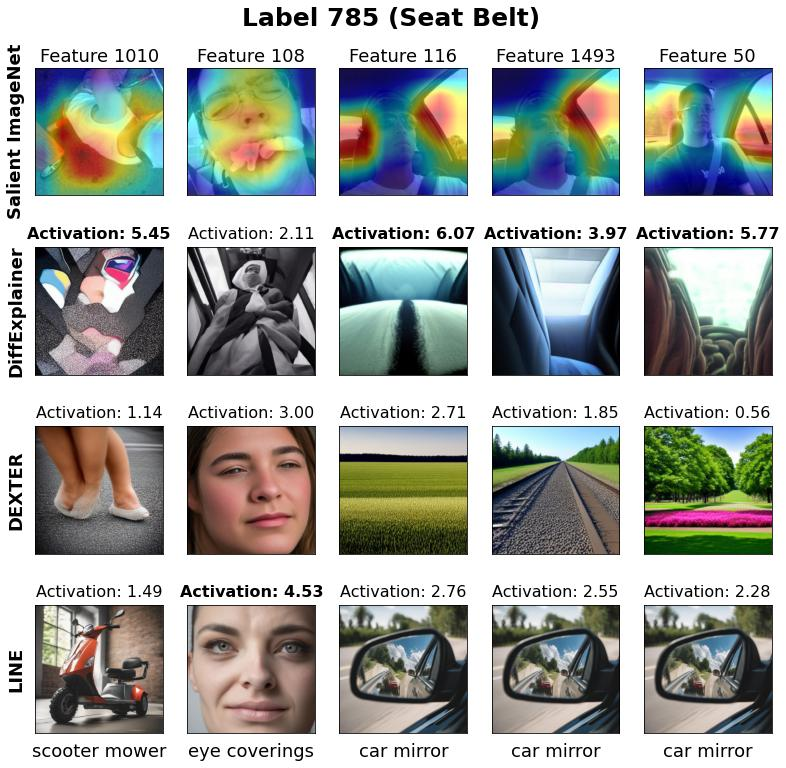

In [5]:
for label in CLASSES:
    draw(label, ["Salient ImageNet", "DiffExplainer", "DEXTER", "LINE"], title=True)